In [3]:
import pandas as pd

# Charger le dataset
file_path = r"C:\Users\islam\OneDrive\Bureau\newpfa\AIML Dataset.csv"
df = pd.read_csv(file_path)

# Aperçu des 5 premières lignes
print("Aperçu du dataset :")
print(df.head())

# Infos générales
print("\nInfos du dataset :")
print(df.info())

# Vérifier les valeurs manquantes
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())

#tyoe es categorielle faut faire one hot encoding

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\islam\\OneDrive\\Bureau\\newpfa\\AIML Dataset.csv'

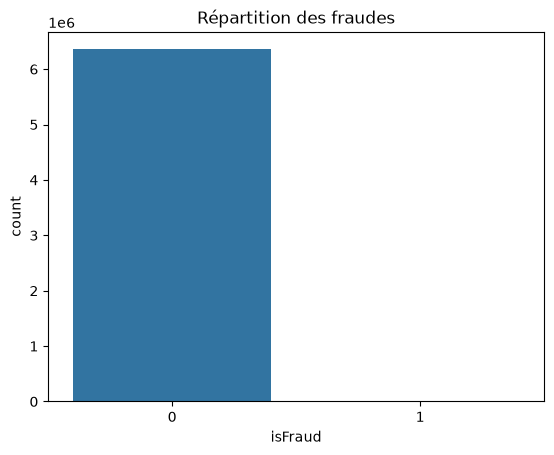

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='isFraud', data=df)
plt.title("Répartition des fraudes")
plt.show()

#majorité des transactions sont normales
# Les fraudes sont très rares

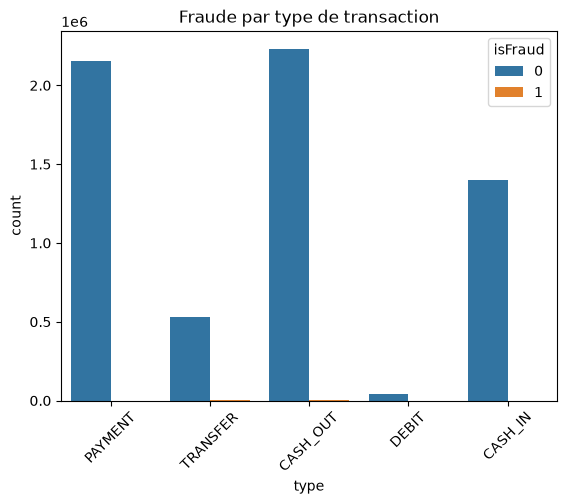

In [ ]:
sns.countplot(x='type', hue='isFraud', data=df)
plt.title("Fraude par type de transaction")
plt.xticks(rotation=45)
plt.show()

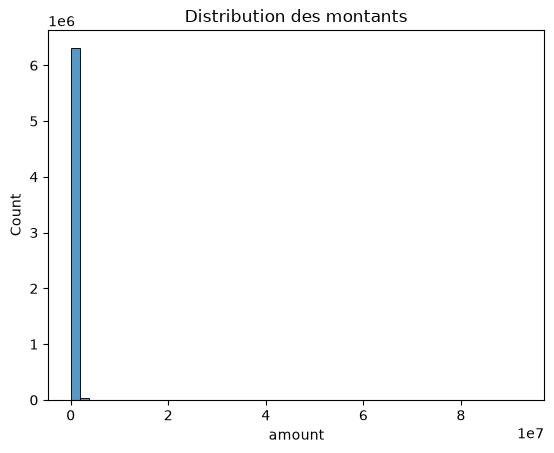

In [ ]:

sns.histplot(df['amount'], bins=50)
plt.title("Distribution des montants")
plt.show()

In [ ]:
#2 pretraitement des données
# Supprimer les colonnes inutiles
df_model = df.drop(['nameOrig', 'nameDest'], axis=1)

print(df_model.head())

   step      type    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   PAYMENT   9839.64       170136.0       160296.36             0.0   
1     1   PAYMENT   1864.28        21249.0        19384.72             0.0   
2     1  TRANSFER    181.00          181.0            0.00             0.0   
3     1  CASH_OUT    181.00          181.0            0.00         21182.0   
4     1   PAYMENT  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  isFraud  isFlaggedFraud  
0             0.0        0               0  
1             0.0        0               0  
2             0.0        1               0  
3             0.0        1               0  
4             0.0        0               0  


In [ ]:
# One-Hot Encoding de la colonne 'type'
df_model = pd.get_dummies(df_model, columns=['type'], drop_first=True)

# Vérifier les nouvelles colonnes
print(df_model.head())

   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  isFraud  isFlaggedFraud  type_CASH_OUT  type_DEBIT  \
0             0.0        0               0          False       False   
1             0.0        0               0          False       False   
2             0.0        1               0          False       False   
3             0.0        1               0           True       False   
4             0.0        0               0          False       False   

   type_PAYMENT  type_TRANSFER  
0          True          False  
1          True          False  
2         False           True  
3         False     

In [ ]:
# Variable cible
y = df_model['isFraud']

# Features
X = df_model.drop(['isFraud', 'isFlaggedFraud'], axis=1)

print("Features :")
print(X.head())
print("\nVariable cible :")
print(y.head())

#separer les features et la variable cible

Features :
   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  
0             0.0          False       False          True          False  
1             0.0          False       False          True          False  
2             0.0          False       False         False           True  
3             0.0           True       False         False          False  
4             0.0          False       False          True          False  

Variable cible :
0    0
1    0
2    1
3    1
4    0
Name: isFraud, dtype: int64


In [ ]:
#3 etape : split train test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

Shape X_train: (5090096, 10)
Shape X_test : (1272524, 10)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cols_num = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

# Fit sur train seulement, transform sur train ET test
X_train[cols_num] = scaler.fit_transform(X_train[cols_num])
X_test[cols_num] = scaler.transform(X_test[cols_num])

print("Standardisation appliquée correctement !")
print(X_train.head())

Standardisation appliquée correctement !
         step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
292779     15 -0.282169      -0.273409       -0.280706       -0.323308   
499763     20 -0.287248      -0.288733       -0.292451       -0.323308   
2970411   231  0.300938      -0.288733       -0.292451       -0.179414   
3137549   236 -0.286868      -0.288733       -0.292451       -0.323308   
1500682   143  0.063257       4.229095        4.244653        0.393047   

         newbalanceDest  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
292779        -0.333104          False       False          True   
499763        -0.333104          False       False          True   
2970411       -0.101671           True       False         False   
3137549       -0.333104          False       False          True   
1500682        0.270692          False       False         False   

         type_TRANSFER  
292779           False  
499763           False  
2970411          False  
31375

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# SMOTE — échantillonnage intelligent (toutes fraudes + 50x normales)
import warnings
warnings.filterwarnings('ignore')

n_fraudes = y_train.sum()
idx_fraudes = y_train[y_train == 1].index
idx_normales = y_train[y_train == 0].sample(n=n_fraudes * 50, random_state=42).index
idx_sample = idx_fraudes.append(idx_normales)

X_sample = X_train.loc[idx_sample]
y_sample = y_train.loc[idx_sample]

print(f"Avant SMOTE — Fraudes: {y_sample.sum()}, Normales: {(y_sample==0).sum()}")

smote = SMOTE(random_state=42, k_neighbors=5)
X_res, y_res = smote.fit_resample(X_sample, y_sample)

print(f"Après SMOTE — Fraudes: {y_res.sum()}, Normales: {(y_res==0).sum()}")

# Modèle avec class_weight balanced
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    max_depth=20
)
rf_model.fit(X_res, y_res)
print("Modèle entraîné !")

Avant SMOTE — Fraudes: 6570, Normales: 328500
Après SMOTE — Fraudes: 328500, Normales: 328500
Modèle entraîné !


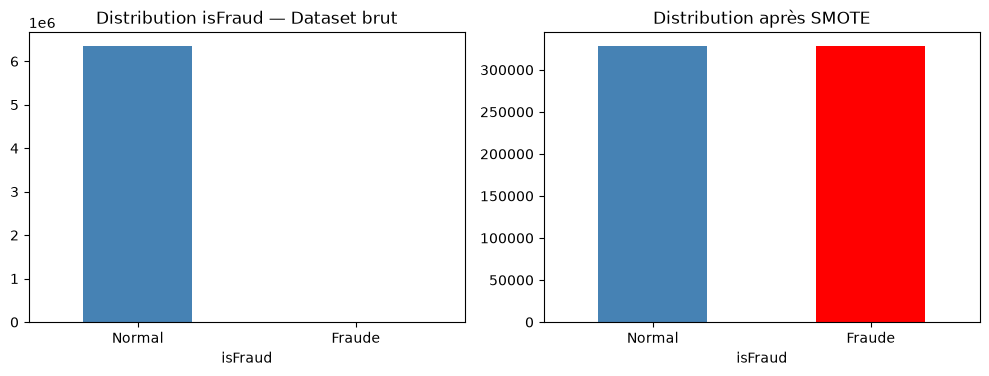

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))
df['isFraud'].value_counts().plot(kind='bar', ax=ax1, color=['steelblue','red'])
ax1.set_title("Distribution isFraud — Dataset brut")
ax1.set_xticklabels(['Normal','Fraude'], rotation=0)
pd.Series(y_res).value_counts().plot(kind='bar', ax=ax2, color=['steelblue','red'])
ax2.set_title("Distribution après SMOTE")
ax2.set_xticklabels(['Normal','Fraude'], rotation=0)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()

In [ ]:

# Évaluation
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print("Rapport de classification :")
print(classification_report(y_test, y_pred, target_names=['Normal','Fraude']))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))

# Sauvegarde
joblib.dump(rf_model, "rf_model_balanced.pkl")
joblib.dump(scaler, "scaler.pkl")

feature_names = list(X.columns)
joblib.dump(feature_names, "feature_names.pkl")

print("Modèle, scaler et features sauvegardés !")
print("Features:", feature_names)

Rapport de classification :
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00   1270881
      Fraude       0.25      0.99      0.39      1643

    accuracy                           1.00   1272524
   macro avg       0.62      0.99      0.70   1272524
weighted avg       1.00      1.00      1.00   1272524

ROC-AUC: 0.999749261452684
Modèle, scaler et features sauvegardés !
Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


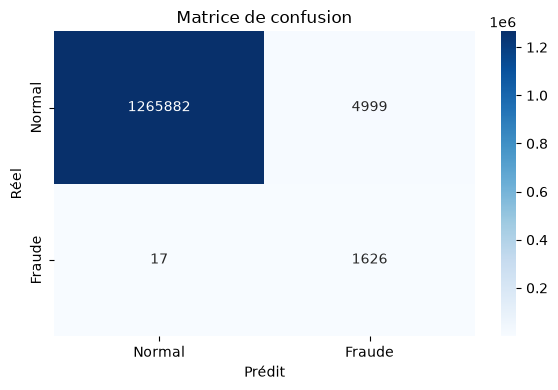

In [ ]:

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Fraude'],
            yticklabels=['Normal','Fraude'])
plt.title('Matrice de confusion')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

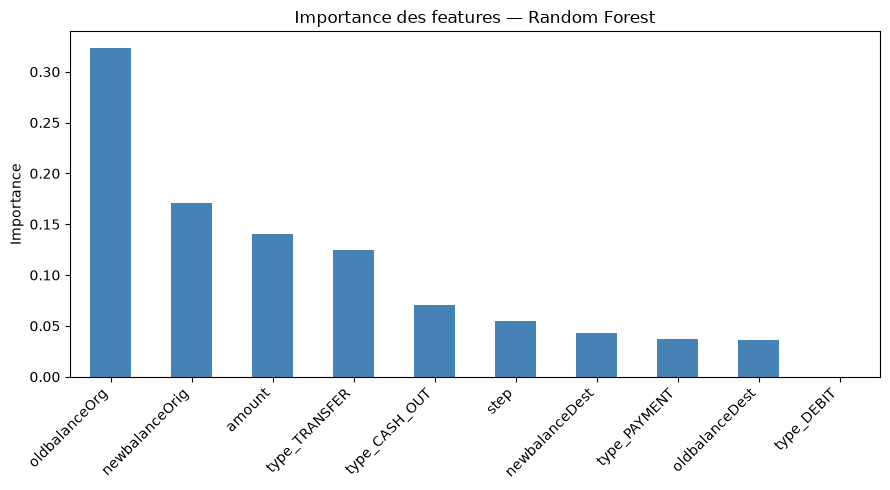

In [ ]:


feat_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(9,5))
feat_imp.plot(kind='bar', color='steelblue')
plt.title("Importance des features — Random Forest")
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

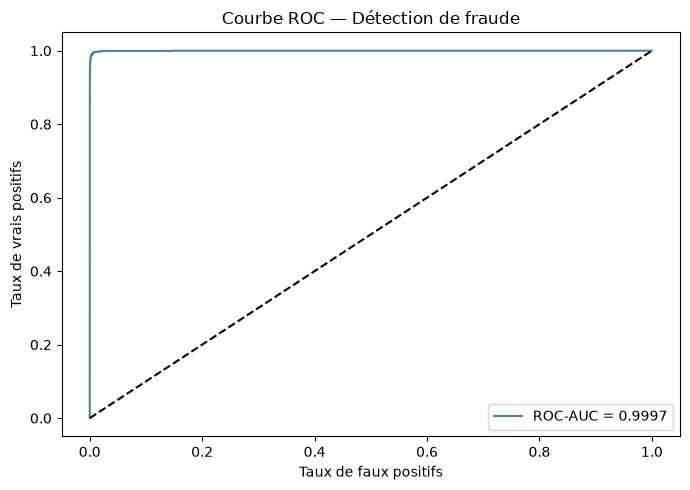

In [ ]:

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='steelblue', label=f'ROC-AUC = {roc_auc_score(y_test, y_proba):.4f}')
plt.plot([0,1],[0,1], 'k--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbe ROC — Détection de fraude')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150)
plt.show()

In [ ]:
import joblib
import pandas as pd

rf_model = joblib.load(r"C:\Users\islam\OneDrive\Bureau\newpfaProject\newpfa\rf_model_balanced.pkl")

row = {
    "step": 1,
    "amount": 9000000,
    "oldbalanceOrg": 9000000,
    "newbalanceOrig": 0,
    "oldbalanceDest": 0,
    "newbalanceDest": 0,
    "type_CASH_OUT": 1,
    "type_DEBIT": 0,
    "type_PAYMENT": 0,
    "type_TRANSFER": 0,
}

df = pd.DataFrame([row])
pred = rf_model.predict(df)[0]
proba = rf_model.predict_proba(df)[0]

print("Prédiction :", "FRAUDE" if pred == 1 else "NORMALE")
print("Probabilités [normale, fraude] :", proba)

Prédiction : NORMALE
Probabilités [normale, fraude] : [0.69 0.31]
